# Machine Learning - Lab Assignment
## Linear Regression, Ridge and Lasso

Name: AbdelMohsen Ahmedsalah    Group: 01-AI /   Date: 11/11/2026

Use Python 3 and Jupyter Notebook. Required packages: `numpy`, `pandas`, `matplotlib`, and `scikit-learn`. If needed, install them with `pip install numpy pandas matplotlib scikit-learn`.

Work through the tasks in order. Create the dataset in Task 1; no external file is needed.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Task 1. Generate the dataset

Create a DataFrame named `df` with 500 synthetic salary records:

- Set the NumPy random seed to **42**.
- Generate 500 integers for `YearsOfExperience`, between **2 and 20 inclusive**, with `np.random.randint(2, 21, size=500)`.
- Set `intercept = 60000` and `slope = (200000 - 60000) / (20 - 2)`.
- Generate 500 noise values from a normal distribution using `np.random.normal(0, 10000, size=500)`.
- Compute `Salary = intercept + slope * YearsOfExperience + noise`.
- Use pandas to create `df` with exactly two columns: `YearsOfExperience` and `Salary`. Display its first five rows and check that its shape is `(500, 2)`.

Generate the experience values **before** generating the noise. Do not load a dataset from a file.

In [2]:
np.random.seed(42)

YearsOfExperience = np.random.randint(2, 21, size=500)

intercept = 60000
slope = (200000 - 60000) / (20 - 2)

noise = np.random.normal(0, 10000, size=500)

Salary = intercept + slope * YearsOfExperience + noise


df = pd.DataFrame({
    "YearsOfExperience": np.round(YearsOfExperience, 2),
    "Salary": np.round(Salary, 2)
})

print(df.head())


   YearsOfExperience     Salary
0                  8  115037.78
1                 16  182309.97
2                 12  156442.41
3                  9  144753.56
4                  8  130798.82


### Task 2. Explore the dataset

Display the dataset shape, summary statistics and number of missing values in each column. Calculate the correlation between `YearsOfExperience` and `Salary`.

In [3]:
print("Shape:")
print(df.shape)

print("\nSummary Statistics:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nCorrelation:")
print(df["YearsOfExperience"].corr(df["Salary"]))

Shape:
(500, 2)

Summary Statistics:
       YearsOfExperience         Salary
count         500.000000     500.000000
mean           10.616000  142570.011040
std             5.662922   44935.263068
min             2.000000   54881.130000
25%             5.750000  104426.297500
50%            10.000000  139865.035000
75%            16.000000  182341.125000
max            20.000000  241879.380000

Missing Values:
YearsOfExperience    0
Salary               0
dtype: int64

Correlation:
0.9750584571962041


### Task 3. Plot the data

Draw a scatter plot with `YearsOfExperience` on the x-axis and `Salary` on the y-axis. Add axis labels and a title.

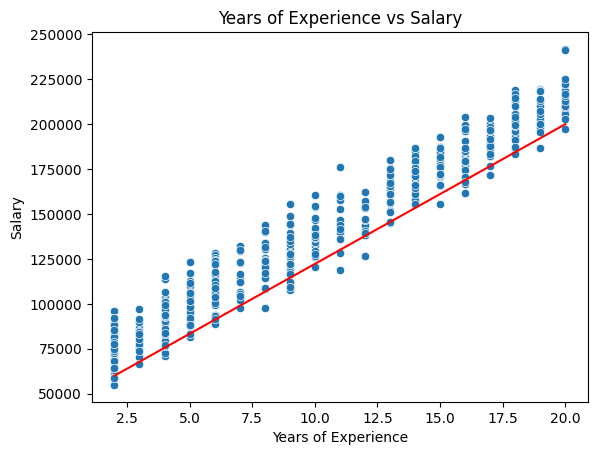

In [6]:
sns.scatterplot(data=df, x="YearsOfExperience", y="Salary")

# Plot the slope
x = [2, 20]
y = [intercept, 200000]

plt.plot(x, y, color="red")


plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Years of Experience vs Salary")

plt.show()

### Task 4. Split the dataset

Set `X` to the `YearsOfExperience` column as a two-dimensional DataFrame and `y` to `Salary`. Use `train_test_split` with `test_size=0.20` and `random_state=42`. Display the number of training and test records.

In [7]:
X = df[["YearsOfExperience"]]
y = df["Salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 400
Testing records: 100


### Task 5. Train linear regression

Fit a `LinearRegression` model on the training data. Display the slope, intercept, training R2 and test R2.

In [8]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

print("Training R2:", model.score(X_train, y_train))
print("Test R2:", model.score(X_test, y_test))

Slope: 7696.612924530549
Intercept: 60961.34084808946
Training R2: 0.9488372177595329
Test R2: 0.9573704718231548


### Task 6. Evaluate linear regression

Predict salary for the test set. Calculate MAE, MSE, RMSE and R2. Display the first five actual and predicted salaries in a table.

In [9]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)

results = pd.DataFrame({
    "Actual Salary": y_test,
    "Predicted Salary": y_pred
})

print(results.head())

MAE: 7905.115226337768
MSE: 93933285.99160862
RMSE: 9691.918591878939
R2: 0.9573704718231548
     Actual Salary  Predicted Salary
361      123631.23     107141.018395
73       139775.63     122534.244244
374       93184.81     107141.018395
155      166740.80     161017.308867
104      174587.18     184107.147641


### Task 7. Compare with a baseline

Use the mean of `y_train` as the predicted salary for every test record. Compute baseline MAE and RMSE and compare them with linear regression.

In [10]:
baseline_pred = np.full(len(y_test), y_train.mean())

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)

print("Linear Regression MAE:", mae)
print("Linear Regression RMSE:", rmse)

Baseline MAE: 40444.958049500005
Baseline RMSE: 46953.769526658456
Linear Regression MAE: 7905.115226337768
Linear Regression RMSE: 9691.918591878939


### Task 8. Plot predictions and residuals

Make two graphs: (a) test observations and the fitted regression line; (b) residuals (`actual - predicted`) against years of experience, with a horizontal line at zero.

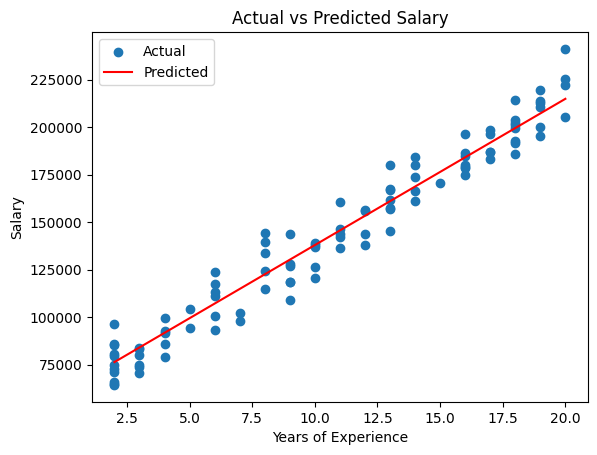

In [11]:
sorted_data = X_test.sort_values("YearsOfExperience")
sorted_pred = model.predict(sorted_data)

plt.scatter(X_test, y_test, label="Actual")
plt.plot(sorted_data, sorted_pred, color="red", label="Predicted")

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Actual vs Predicted Salary")
plt.legend()
plt.show()

### Task 9. Predict new salaries

Use the linear regression model to predict salaries for **5, 10 and 15 years** of experience. Display the results in a table.

In [12]:
new_data = pd.DataFrame({
    "YearsOfExperience": [5, 10, 15]
})

new_predictions = model.predict(new_data)

prediction_table = pd.DataFrame({
    "YearsOfExperience": [5, 10, 15],
    "Predicted Salary": new_predictions
})

print(prediction_table)

   YearsOfExperience  Predicted Salary
0                  5      99444.405471
1                 10     137927.470093
2                 15     176410.534716


### Task 10. Standardize the feature

Use `StandardScaler` on `X_train` and `X_test`. Fit the scaler on the training set only, then transform both sets. Keep the target `y` unchanged.

In [13]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data after scaling:")
print(X_train_scaled[:5])

print("Testing data after scaling:")
print(X_test_scaled[:5])

Training data after scaling:
[[ 1.14441709]
 [-0.45865743]
 [ 0.07570074]
 [-1.52737378]
 [-1.171135  ]]
Testing data after scaling:
[[-0.81489621]
 [-0.45865743]
 [-0.81489621]
 [ 0.43193952]
 [ 0.9662977 ]]


### Task 11. Train Ridge regression

Fit two `Ridge` models on the scaled training set, using `alpha=10` and `alpha=100`. For each model, display its coefficient, test MAE and test R2. Compare the coefficients. Keep the `alpha=10` model for Task 13.

In [14]:
ridge10 = Ridge(alpha=10)
ridge10.fit(X_train_scaled, y_train)

ridge100 = Ridge(alpha=100)
ridge100.fit(X_train_scaled, y_train)

ridge10_pred = ridge10.predict(X_test_scaled)
ridge100_pred = ridge100.predict(X_test_scaled)

print("Ridge alpha = 10")
print("Coefficient:", ridge10.coef_[0])
print("MAE:", mean_absolute_error(y_test, ridge10_pred))
print("R2:", r2_score(y_test, ridge10_pred))

print("\nRidge alpha = 100")
print("Coefficient:", ridge100.coef_[0])
print("MAE:", mean_absolute_error(y_test, ridge100_pred))
print("R2:", r2_score(y_test, ridge100_pred))

Ridge alpha = 10
Coefficient: 42156.50311578086
MAE: 8084.4618341650885
R2: 0.9557273886824492

Ridge alpha = 100
Coefficient: 34568.33255494031
MAE: 11308.370134709758
R2: 0.9118378125714741


### Task 12. Train Lasso regression

Fit three `Lasso` models on the scaled training set, using `alpha=1000`, `alpha=10000` and `alpha=50000`. Set `max_iter=20000`. For each model, display its coefficient, test MAE and test R2. Observe what happens to the coefficient as alpha increases. Keep the `alpha=1000` model for Task 13.

In [15]:
lasso1000 = Lasso(alpha=1000, max_iter=20000)
lasso10000 = Lasso(alpha=10000, max_iter=20000)
lasso50000 = Lasso(alpha=50000, max_iter=20000)

lasso1000.fit(X_train_scaled, y_train)
lasso10000.fit(X_train_scaled, y_train)
lasso50000.fit(X_train_scaled, y_train)

lasso1000_pred = lasso1000.predict(X_test_scaled)
lasso10000_pred = lasso10000.predict(X_test_scaled)
lasso50000_pred = lasso50000.predict(X_test_scaled)

print("Lasso alpha = 1000")
print("Coefficient:", lasso1000.coef_[0])
print("MAE:", mean_absolute_error(y_test, lasso1000_pred))
print("R2:", r2_score(y_test, lasso1000_pred))

print("\nLasso alpha = 10000")
print("Coefficient:", lasso10000.coef_[0])
print("MAE:", mean_absolute_error(y_test, lasso10000_pred))
print("R2:", r2_score(y_test, lasso10000_pred))

print("\nLasso alpha = 50000")
print("Coefficient:", lasso50000.coef_[0])
print("MAE:", mean_absolute_error(y_test, lasso50000_pred))
print("R2:", r2_score(y_test, lasso50000_pred))

Lasso alpha = 1000
Coefficient: 42210.415693675386
MAE: 8074.651902991405
R2: 0.9558377967182283

Lasso alpha = 10000
Coefficient: 33210.415693675386
MAE: 12287.962903568034
R2: 0.8980447952707716

Lasso alpha = 50000
Coefficient: 0.0
MAE: 40444.958049500005
R2: -0.000534200776193483


### Task 13. Compare the models

Create a table showing test MAE, RMSE and R2 for: the mean baseline, linear regression, Ridge (`alpha=10`) and Lasso (`alpha=1000`). Write two sentences about the results.

In [16]:
baseline_pred = np.full(len(y_test), y_train.mean())

models_results = {
    "Model": ["Baseline", "Linear Regression", "Ridge", "Lasso"],
    "MAE": [
        mean_absolute_error(y_test, baseline_pred),
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test, ridge10_pred),
        mean_absolute_error(y_test, lasso1000_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_pred)),
        np.sqrt(mean_squared_error(y_test, y_pred)),
        np.sqrt(mean_squared_error(y_test, ridge10_pred)),
        np.sqrt(mean_squared_error(y_test, lasso1000_pred))
    ],
    "R2": [
        r2_score(y_test, baseline_pred),
        r2_score(y_test, y_pred),
        r2_score(y_test, ridge10_pred),
        r2_score(y_test, lasso1000_pred)
    ]
}

comparison = pd.DataFrame(models_results)

print(comparison)

               Model           MAE          RMSE        R2
0           Baseline  40444.958050  46953.769527 -0.000534
1  Linear Regression   7905.115226   9691.918592  0.957370
2              Ridge   8084.461834   9876.932003  0.955727
3              Lasso   8074.651903   9864.608658  0.955838


**Submission:** Save the notebook with your code, results and plots. Include your short comparison for Task 13.